# GP2 Bioinformatics Training Workshop Argentina  

## Whole-Genome Data Analysis - CNV calling

<span style="background-color: #90EE90">GP2 ❤️ Open Science 😍</span>

**Module:** Copy Number Variant Calling

**Author:** Carlos Hernández and Zih-Hua Fang on behalf of the Global Parkinson's Genetics Program (ASAP)

**Estimated Computation and Runtime:**

**Estimated Specifications:** Default; 4 CPU,  15 GB Memory, 50 GB Persistent Disk Size  
**Estimated Runtime:** 30 min.  
**Date Last Updated:** 09/07/2026

## Notebook Summary

##### 2. [Getting Started](##2)
This section goes through:

- Set up environment
- Manta (https://github.com/Illumina/manta)
- Prepare inputs that are required for Manta to workspace

##### 3. [Run Manta on PRKN Region](##2)
This section goes through:

- Call SV in PRKN region starting from Crams
- Read the output to interprete the results

## Getting Started 

### Set up environment

In [ ]:
# Use the os package to interact with the environment
import os

# Bring in Pandas for Dataframe functionality
import pandas as pd

# Numpy for basics
import numpy as np

# Use StringIO for working with file contents
from io import StringIO

# Enable IPython to display matplotlib graphs
import matplotlib.pyplot as plt
%matplotlib inline

#Import Sys
import sys as sys

from pathlib import Path

### Install Manta

In [ ]:
# Point mamba/conda to a package cache the current user owns
os.environ["CONDA_PKGS_DIRS"] = os.path.expanduser("~/.conda/pkgs")

In [ ]:
mamba create -n manta -c bioconda -c conda-forge manta=1.6.0 python=2.7 samtools -y

## Prepare inputs that are required for Manta to workspace

In [ ]:
# Ws-files path
ws_files = '/home/jupyter/workspace/ws_files'

# define google bucket paths for the files
ref_genome       = "gs://gcp-public-data--broad-references/hg38/v0/Homo_sapiens_assembly38.fasta"
ref_genome_index = "gs://gcp-public-data--broad-references/hg38/v0/Homo_sapiens_assembly38.fasta.fai"
cram1            = "ftp://ftp.sra.ebi.ac.uk/vol1/run/ERR323/ERR3239351/NA18522.final.cram" 
cram1_index      = "ftp://ftp.sra.ebi.ac.uk/vol1/run/ERR323/ERR3239351/NA18522.final.cram.crai"
cram2            = "ftp://ftp.sra.ebi.ac.uk/vol1/run/ERR324/ERR3242196/HG01889.final.cram" 
cram2_index      = "ftp://ftp.sra.ebi.ac.uk/vol1/run/ERR324/ERR3242196/HG01889.final.cram.crai"
genecode         = "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_44/gencode.v44.annotation.gtf.gz"

if not os.path.exists(f"{ws_files}/Reference/Homo_sapiens_assembly38.fasta"):
    !gsutil -m cp {ref_genome} {ws_files}/Reference

if not os.path.exists(f"{ws_files}/Reference/Homo_sapiens_assembly38.fasta.fai"):
    !gsutil -m cp {ref_genome_index} {ws_files}/Reference

if not os.path.exists(f"{ws_files}/CRAMs/{os.path.basename(cram1)}"):
    !wget {cram1} -O {ws_files}/CRAMs/{os.path.basename(cram1)}

if not os.path.exists(f"{ws_files}/CRAMs/{os.path.basename(cram1_index)}"):
    !wget {cram1_index} -O {ws_files}/CRAMs/{os.path.basename(cram1_index)}

if not os.path.exists(f"{ws_files}/CRAMs/{os.path.basename(cram2)}"):
    !wget {cram2} -O {ws_files}/CRAMs/{os.path.basename(cram2)}

if not os.path.exists(f"{ws_files}/CRAMs/{os.path.basename(cram2_index)}"):
    !wget {cram2_index} -O {ws_files}/CRAMs/{os.path.basename(cram2_index)}

if not os.path.exists(f"{ws_files}/Reference/{os.path.basename(genecode)}"):
    !wget {genecode} -O {ws_files}/Reference/{os.path.basename(genecode)}


### Add your name and create a directory for your analysis

In [ ]:
traineeID = "your_name"
WORK_DIR = f"/home/jupyter/workspace/ws_files/INTERMEDIATE_LEVEL_WORKSHOP/CNV_calling_{traineeID}"
! mkdir -p {WORK_DIR}

In [ ]:
os.chdir(WORK_DIR)

## Overview of Copy Number Variants

### Copy Number Variants (CNVs)

**Definition:** Structural variants involving a gain (duplication) or loss 
(deletion) of a genomic segment, typically ≥50 bp, relative to a reference 
genome. Unlike SNVs, CNVs alter gene dosage — the number of copies of the 
affected region — which can disrupt gene function even without changing the 
underlying sequence.

**Relevance:**
- Common mechanism in Mendelian disease (e.g., PRKN exon deletions/duplications 
  causing autosomal recessive Parkinson's disease)
- Detected from short-read WGS via read-depth, split-read, and discordant 
  read-pair signals (tools: Manta, CNVnator, GATK-gCNV)
- Complement STR/SNV analysis — often missed by standard small-variant callers, 
  so dedicated SV/CNV calling is required

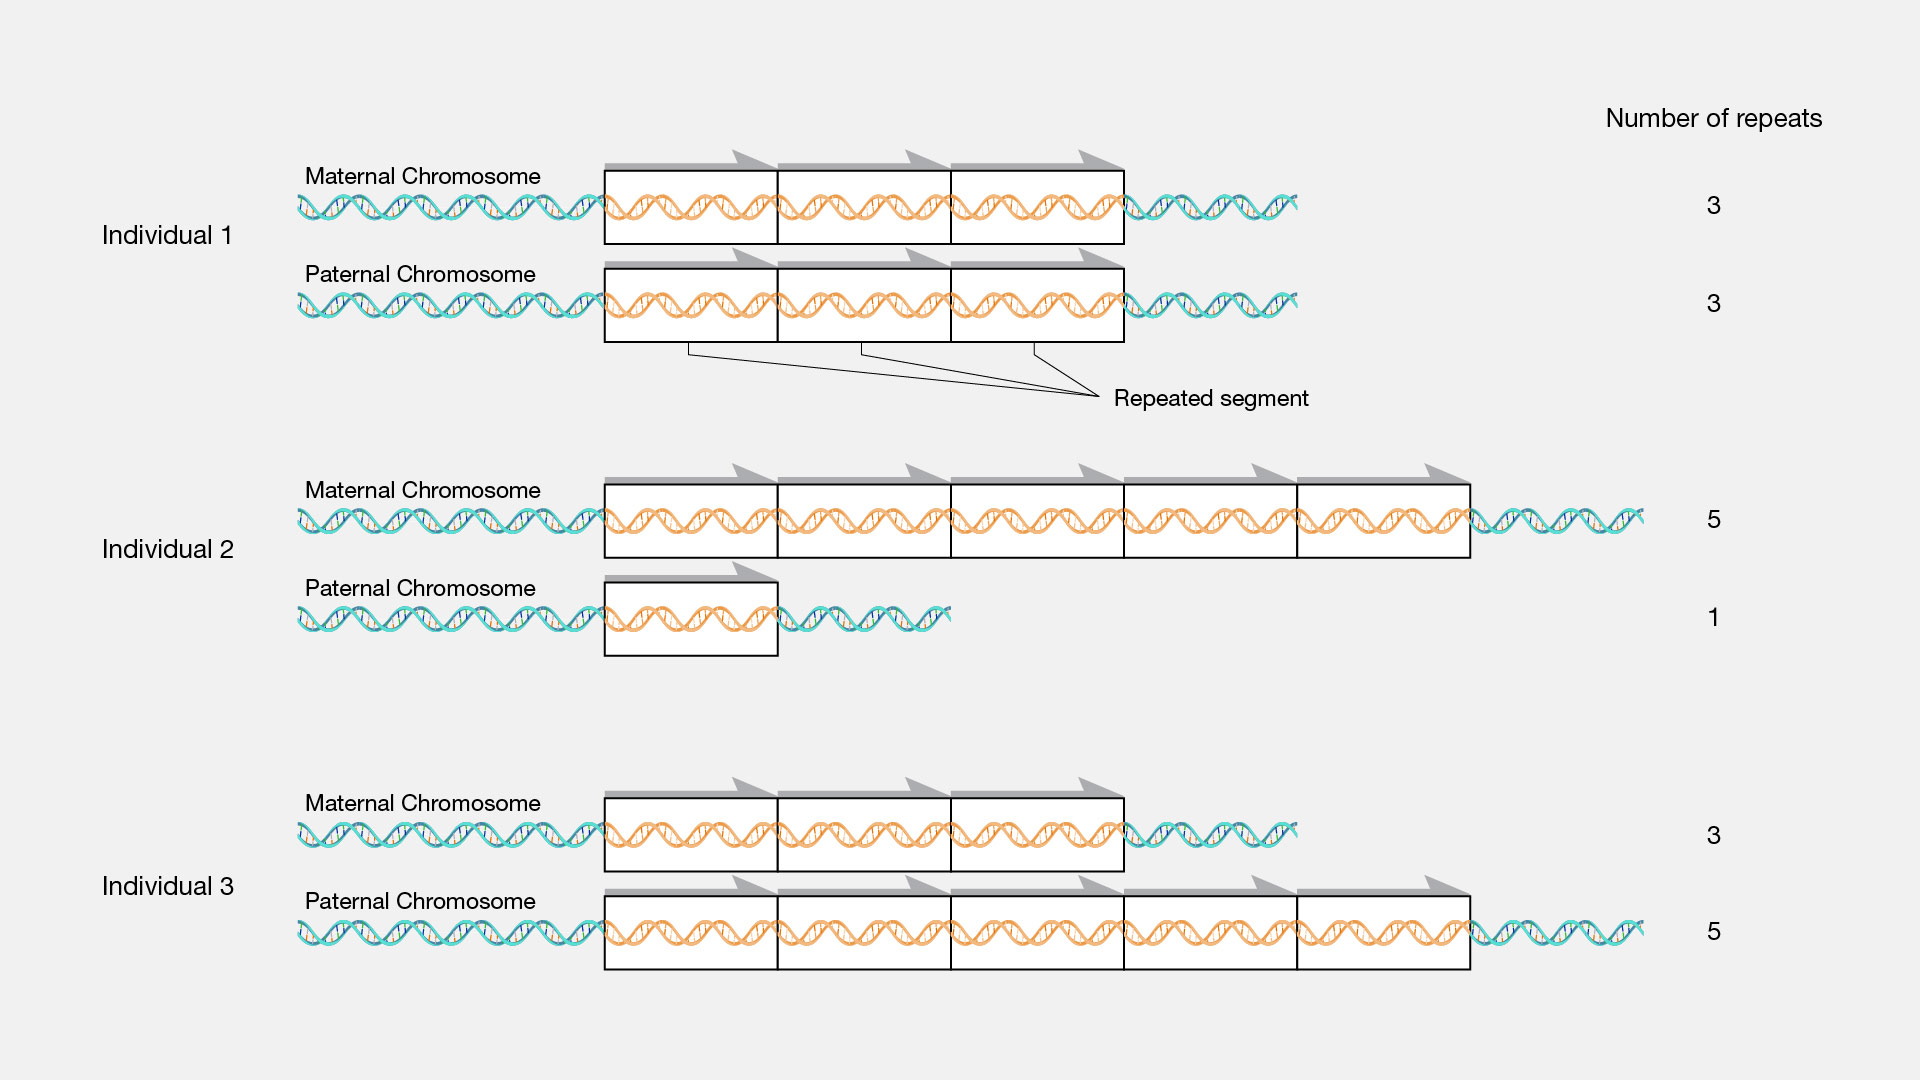

### CNV Detection: Array-based vs. WGS-based

Two main strategies for CNV discovery, depending on the input data:

### 1. Genotyping arrays (LRR/BAF-based) — e.g., **CNV-Finder** (GP2)
Uses normalized signal intensity from Illumina arrays — Log R Ratio (LRR) and 
B Allele Frequency (BAF) — to infer copy number changes. CNV-Finder adds an 
LSTM deep learning model on top to prioritize candidate CNVs in predefined 
genes (PRKN, SNCA, MAPT, APP, LINGO2) before confirming with sequencing.
([GP2 output](https://gp2.org/research-outputs/cnv-finder-streamlining-copy-number-variation-discovery/) · [GitHub](https://github.com/GP2code/CNV-Finder))

**Pros:**
- Very low cost per sample — arrays are cheap and already generated for most 
  GWAS-scale cohorts (no extra sequencing needed)
- Scales to tens/hundreds of thousands of samples easily
- Fast — well suited for large-scale screening/prioritization

**Cons:**
- Resolution limited by probe density — poor detection of small CNVs or 
  CNVs in probe-sparse regions
- Indirect signal (intensity-based) → higher false positive rate, needs 
  human review / ML filtering 
- Breakpoints are imprecise — can't resolve exact CNV boundaries
- Requires orthogonal confirmation (sequencing) for clinical-grade calls

### 2. Whole-genome sequencing (read-depth / split-read) — e.g., **Manta**
Uses read alignment evidence (read-depth, split-reads, discordant pairs) 
directly from BAM/CRAM files.

**Pros:**
- Base-pair-level breakpoint resolution
- Detects CNVs regardless of array probe coverage
- Single data source can also call SNVs/indels — no need for separate assay

**Cons:**
- Sequencing is far more expensive — impractical to screen huge cohorts 
  this way as a first pass
- Sensitivity depends on coverage depth and read length — some CNV sizes/types 
  are harder to call reliably (e.g., short-read blind spots in repetitive 
  regions)
- Computationally heavier per sample

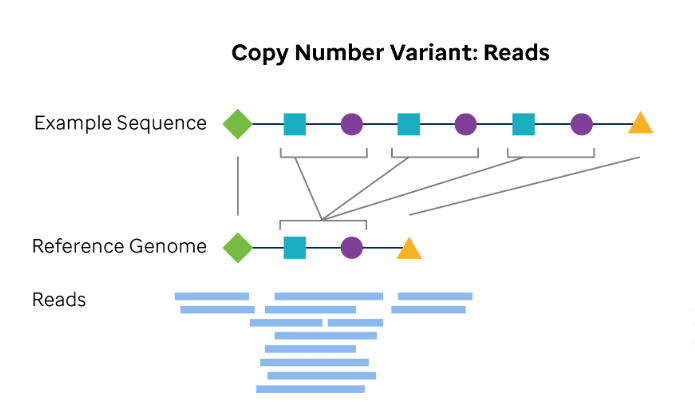

## CNV detection workflow (Manta)

1. **Input:** BAM/CRAM (aligned WGS data), restricted to gene/region of 
   interest for faster runtime
2. **Manta:** performs read-depth, split-read, and discordant-pair analysis 
   → outputs `candidateSV.vcf` (unfiltered) and `diploidSV.vcf` (genotyped)
3. **Filtering:** keep only `diploidSV.vcf` calls; check `PR`/`SR` support 
   and `SVLEN` for confidence
4. **Annotation:** map breakpoints onto exon structure using the gene's 
   MANE Select transcript (e.g., PRKN — ENST00000366898, GENCODE v44)
5. **Downstream:** cross-reference against population SV databases 
   (e.g., gnomAD-SV) to flag likely pathogenic vs. benign CNVs

**Flow:** `BAM/CRAM → Manta → diploidSV.vcf → exon-level annotation → pathogenicity assessment`


## Run Manta on PRKN Region

In [ ]:
%%bash -s {WORK_DIR}
set -euo pipefail

WORK_DIR=$1
ws_files="/home/jupyter/workspace/ws_files"
REF=${ws_files}/Reference/Homo_sapiens_assembly38.fasta
BAMDIR=${WORK_DIR}/prkn_bams
THREADS=1

# PRKN in hg38 with 10 kb flanking on each side
REGION="chr6:161337417-162737802"

mkdir -p "${BAMDIR}"

for SAMPLE in NA18522 HG01889; do
    CRAM=${ws_files}/CRAMs/${SAMPLE}.final.cram
    BAM=${BAMDIR}/${SAMPLE}.PRKN.bam
    RUNDIR=${WORK_DIR}/${SAMPLE}

    # --- Pre-step: transcode the PRKN region CRAM 3.1 -> BAM ---
    # DRAGEN wrote CRAM 3.1, which Manta 1.6.0's bundled htslib (~2019) cannot decode.
    # The env's modern samtools (htslib 1.23) reads it fine; BAM sidesteps the version issue.
    mamba run -n manta samtools view -b -T "${REF}" \
        "${CRAM}" "${REGION}" \
        -o "${BAM}"
    mamba run -n manta samtools index "${BAM}"

    # configManta.py aborts if runDir exists:
    rm -rf "${RUNDIR}"

    # Step 1: configure the workflow restricted to PRKN
    mamba run -n manta configManta.py \
      --bam "${CRAM}" \
      --referenceFasta "${REF}" \
      --region "${REGION}" \
      --runDir "${RUNDIR}"

    # Step 2: run locally with ${THREADS} jobs
    mamba run -n manta python "${RUNDIR}/runWorkflow.py" \
      -m local \
      -j "${THREADS}"

    echo "== ${SAMPLE} done -> ${RUNDIR}/results/variants/diploidSV.vcf.gz =="
done

### Output formats — CNV detection (WGS-Manta)
- Output: VCF with SV records. Key fields:
  - `SVTYPE` — DEL, DUP, INS, INV, BND
  - `SVLEN` — length of the variant
  - `PR`/`SR` — paired-read and split-read supporting evidence counts
- Manta also outputs a `candidateSV.vcf` (unfiltered) vs. `diploidSV.vcf` 
  (genotyped, higher confidence) — always use the latter for reporting

**Reading tip:** for Manta, check both `PR` and `SR` support — 
calls with only paired-read (no split-read) evidence have less precise 
breakpoints and warrant more caution.

## Read the result

In [ ]:
import gzip
import pandas as pd
from pathlib import Path

# --- Config ---
OUTDIR = Path(f"{WORK_DIR}")
SAMPLES = ["NA18522", "HG01889"]

# PRKN gene body in hg38 (no flanks). Adjust if your annotation differs.
PRKN_CHROM = "chr6"
PRKN_START = 161347417
PRKN_END   = 162727802

# Only these SV types are relevant for copy number
CN_TYPES = {"DEL", "DUP"}


def parse_info(info_str):
    """Turn the INFO column into a dict; flags become True."""
    d = {}
    for field in info_str.split(";"):
        if "=" in field:
            k, v = field.split("=", 1)
            d[k] = v
        else:
            d[field] = True
    return d


def parse_sample(fmt_str, sample_str):
    """Zip FORMAT keys with the sample column values."""
    keys = fmt_str.split(":")
    vals = sample_str.split(":")
    return dict(zip(keys, vals))


def infer_copy_number(svtype, gt):
    """Infer copy number from SVTYPE + genotype. Diploid autosome assumed (CN=2 baseline)."""
    alleles = gt.replace("|", "/").split("/")
    n_alt = alleles.count("1")
    if svtype == "DEL":
        return {2: "CN2 (ref)", 1: "CN1 (het loss)", 0: "CN0 (hom loss)"}.get(2 - n_alt, "?")
    if svtype == "DUP":
        return {0: "CN2 (ref)", 1: "CN3 (het gain)", 2: "CN4+ (hom gain)"}.get(n_alt, "?")
    return "NA"


def overlaps_prkn(chrom, start, end):
    """True if the SV interval intersects the PRKN gene body."""
    return chrom == PRKN_CHROM and start <= PRKN_END and end >= PRKN_START


def read_vcf(path, sample_name):
    """Extract DEL/DUP calls overlapping PRKN from a Manta diploidSV VCF."""
    rows = []
    with gzip.open(path, "rt") as fh:
        for line in fh:
            if line.startswith("#"):
                continue
            cols = line.rstrip("\n").split("\t")
            chrom, pos, _id, ref, alt, qual, flt, info, fmt, sample = cols[:10]
            pos = int(pos)

            info_d = parse_info(info)
            svtype = info_d.get("SVTYPE", "")
            if svtype not in CN_TYPES:
                continue

            # Manta stores the far breakend in INFO/END; SVLEN is negative for DEL
            end = int(info_d.get("END", pos))
            svlen = abs(int(info_d.get("SVLEN", end - pos)))

            if not overlaps_prkn(chrom, pos, end):
                continue

            smp = parse_sample(fmt, sample)
            gt = smp.get("GT", "./.")

            # PR = spanning-pair support (ref,alt); SR = split-read support (ref,alt)
            pr_alt = smp.get("PR", "0,0").split(",")[-1]
            sr_alt = smp.get("SR", "0,0").split(",")[-1] if "SR" in smp else "NA"

            rows.append({
                "sample":   sample_name,
                "id":       _id,
                "chrom":    chrom,
                "start":    pos,
                "end":      end,
                "svtype":   svtype,
                "size_bp":  svlen,
                "filter":   flt,
                "GT":       gt,
                "copy_number_inferred": infer_copy_number(svtype, gt),
                "PR_alt":   pr_alt,   # paired-read evidence for the alt allele
                "SR_alt":   sr_alt,   # split-read evidence for the alt allele
                "qual":     qual,
            })
    return rows


# --- Run over both samples ---
all_rows = []
for s in SAMPLES:
    vcf = OUTDIR / s / "results" / "variants" / "diploidSV.vcf.gz"
    if not vcf.exists():
        print(f"[WARN] missing VCF for {s}: {vcf}")
        continue
    all_rows.extend(read_vcf(vcf, s))

df = pd.DataFrame(all_rows)

if df.empty:
    print("No DEL/DUP calls overlapping PRKN in any sample.")
else:
    # PASS calls are the confident ones; keep the rest visible but flagged
    df = df.sort_values(["sample", "start"]).reset_index(drop=True)
    print(df.to_string(index=False))

    print("\n=== Per-sample summary (PASS only) ===")
    passed = df[df["filter"] == "PASS"]
    for s in SAMPLES:
        sub = passed[passed["sample"] == s]
        if sub.empty:
            print(f"{s}: no PASS CNV in PRKN")
        else:
            for _, r in sub.iterrows():
                print(f"{s}: {r.svtype} {r.size_bp} bp  {r.copy_number_inferred}  "
                      f"(PR_alt={r.PR_alt}, SR_alt={r.SR_alt})")

In [ ]:
# Keep only relevant columns
SVS = (
    df[
        [
            "sample",
            "chrom",
            "start",
            "end",
            "svtype",
            "size_bp"
        ]
    ]
    .sort_values(
        ["sample", "start"]
    )
    .to_dict("records")
)

print(SVS)

In [ ]:
import gzip
import pandas as pd

# --- Config ---
GTF = "/home/jupyter/workspace/ws_files/Reference/gencode.v44.annotation.gtf.gz"
PRKN_GENE_NAMES = {"PRKN", "PARK2"}
MANE_TAG = "MANE_Select"
MANE_TX = "ENST00000366898"  


def grab(attrs, key):
    """Extract a GTF attribute value, handling BOTH quoted ("PRKN") and
    unquoted (exon_number 1) styles that GENCODE mixes in the same line."""
    marker = f"{key} "
    idx = attrs.find(marker)
    if idx == -1:
        return None
    rest = attrs[idx + len(marker):]
    if rest.startswith('"'):                 # quoted value: gene_name "PRKN"
        return rest[1:].split('"', 1)[0]
    return rest.split(";", 1)[0].strip()     # unquoted value: exon_number 1


def load_prkn_mane_exons(gtf_path):
    """PRKN exons from the MANE Select transcript only."""
    opener = gzip.open if str(gtf_path).endswith(".gz") else open
    exons = []
    with opener(gtf_path, "rt") as fh:
        for line in fh:
            if line.startswith("#"):
                continue
            f = line.rstrip("\n").split("\t")
            if f[2] != "exon":
                continue
            attrs = f[8]
            if not any(f'gene_name "{n}"' in attrs for n in PRKN_GENE_NAMES):
                continue
            # keep MANE via tag, or fall back to the explicit transcript id
            if MANE_TAG not in attrs and MANE_TX not in attrs:
                continue
            exons.append({
                "chrom":         f[0],
                "start":         int(f[3]),
                "end":           int(f[4]),
                "strand":        f[6],
                "exon_number":   int(grab(attrs, "exon_number")),
                "transcript_id": grab(attrs, "transcript_id"),
            })
    return pd.DataFrame(exons).sort_values("exon_number").reset_index(drop=True)


def exons_hit(sv, exons_df):
    hit = exons_df[
        (exons_df["chrom"] == sv["chrom"]) &
        (exons_df["start"] <= sv["end"]) &
        (exons_df["end"]   >= sv["start"])
    ]
    return sorted(hit["exon_number"].tolist())


exons = load_prkn_mane_exons(GTF)
if exons.empty:
    raise SystemExit("No PRKN MANE exons found — check GTF path / gene name.")

tx = exons["transcript_id"].iloc[0]
strand = exons["strand"].iloc[0]
n_exons = int(exons["exon_number"].max())
print(f"MANE transcript: {tx} (strand {strand}), {n_exons} exons total")
print("PRKN is on the minus strand — GENCODE numbers biologically (exon 1 = 5').\n")

rows = []
for sv in SVS:
    nums = exons_hit(sv, exons)
    if not nums:
        call = "intronic (no exon hit)"
    elif len(nums) == 1:
        call = f"exon {nums[0]}"
    else:
        call = f"exons {nums[0]}-{nums[-1]}"
    rows.append({
        "sample":       sv["sample"],
        "region":       f"{sv['chrom']}:{sv['start']}-{sv['end']}",
        "size_bp":      sv["size_bp"],
        "exons_hit":    call,
        "n_exons_hit":  len(nums),
        "exon_numbers": nums,
    })

print(pd.DataFrame(rows).to_string(index=False))

## QC and common pitfalls — CNV analysis (Manta)

- **CRAM version incompatibilities:** CRAM 3.1 produced by newer DRAGEN 
  versions (e.g., 4.4.7) may not be readable by the htslib bundled with Manta — 
  pre-transcode the region to BAM if genotyping fails silently or crashes
- **Read-depth signal limitations:** struggles in GC-rich or repetitive/ 
  low-complexity regions — cross-check calls using split-read (`SR`) and 
  discordant paired-read (`PR`) support, not depth alone
- **Small CNVs near the size floor (~50 bp):** harder to call reliably with 
  short reads — consider orthogonal long-read validation for borderline calls
- **Unfiltered vs. genotyped output:** always use `diploidSV.vcf` (genotyped) 
  rather than `candidateSV.vcf` (unfiltered candidates) for reporting — the 
  candidate file includes many low-confidence calls
- **Population-level benign CNVs:** cross-reference calls against population 
  SV databases (e.g., gnomAD-SV) before flagging as pathogenic — some deletions/ 
  duplications are common benign polymorphisms, even within disease genes
- **Restricting analysis to a single gene region:** speeds up runtime and 
  reduces noise, but be aware Manta's background model is tuned for genome-wide 
  calling — region-restricted runs may need manual review of borderline calls